# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Sandi Suryo Nugroho | 5054251020 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
df = pd.read_csv("Mall_Customers.csv")

print("5 baris pertama:")
display(df.head())

print("\nJumlah baris/kolom:", df.shape)

print("\nTipe data:")
print(df.dtypes)

print("\nStatistik deskriptif:")
display(df.describe())

print("\nJumlah missing value per kolom:")
print(df.isna().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

5 baris pertama:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Jumlah baris/kolom: (200, 5)

Tipe data:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Statistik deskriptif:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0


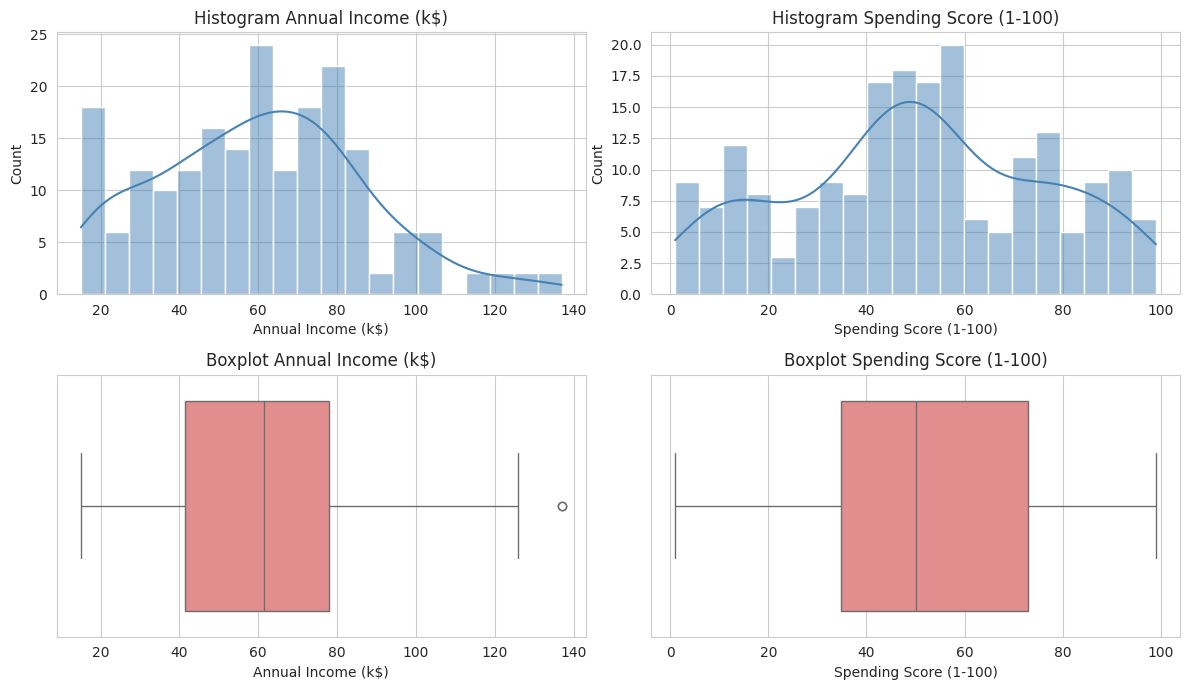

Annual Income (k$): min=15, max=137, skewness=0.32, outlier IQR=2
Spending Score (1-100): min=1, max=99, skewness=-0.05, outlier IQR=0


In [3]:
FEATURES = ["Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, col in enumerate(FEATURES):
    sns.histplot(df[col], bins=20, kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Histogram {col}")
    sns.boxplot(x=df[col], ax=axes[1, i], color="lightcoral")
    axes[1, i].set_title(f"Boxplot {col}")
plt.tight_layout()
plt.show()

# Deteksi outlier dengan aturan IQR (hanya untuk pengamatan, data tidak dihapus)
for col in FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(f"{col}: min={df[col].min()}, max={df[col].max()}, skewness={df[col].skew():.2f}, outlier IQR={len(outlier)}")

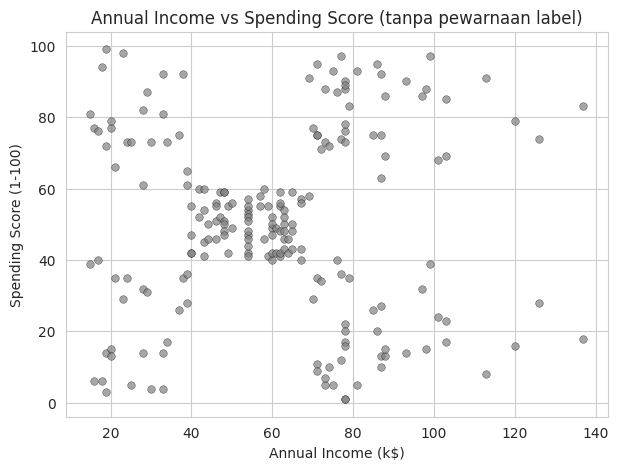

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(df[FEATURES[0]], df[FEATURES[1]], s=30, alpha=0.7, color="gray", edgecolor="k", linewidth=0.3)
plt.xlabel(FEATURES[0])
plt.ylabel(FEATURES[1])
plt.title("Annual Income vs Spending Score (tanpa pewarnaan label)")
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban:**

- **Missing value & duplikat:** tidak ada
- **Rentang:** `Annual Income` 15–137 k$ (mean 60.56, median 61.5, std 26.26). `Spending Score` 1–99 (mean 50.2, median 50, std 25.82).
- **Bentuk distribusi & outlier:** Income sedikit miring ke kanan (skewness 0.32) dengan 2 outlier menurut aturan IQR di sisi atas (sekitar 137 k$). Spending Score hampir simetris (skewness -0.05) dan tidak punya outlier.
- **Kelompok terpisah:** ya. Scatter plot memperlihatkan sekitar 5 kelompok: satu blok besar di tengah (income dan spending menengah) serta empat kelompok di sudut-sudutnya (income rendah/tinggi × spending rendah/tinggi). Dua fitur ini cukup menunjukkan struktur cluster yang jelas.

# 2. Preprocessing

In [5]:
# Dari EDA: tidak ada missing value dan tidak ada duplikat, tetapi tetap ditangani secara defensif.
df_clean = df.dropna().drop_duplicates().reset_index(drop=True)
print("Baris sebelum:", len(df), "| sesudah:", len(df_clean))

# CustomerID dan Gender tidak dipakai sebagai fitur clustering
X = df_clean[FEATURES].copy()
print("Bentuk X:", X.shape)
display(X.head())

Baris sebelum: 200 | sesudah: 200
Bentuk X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
scaler = StandardScaler()
X_scaled_arr = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_arr, columns=X.columns)

print("Beberapa baris X_scaled:")
display(X_scaled.head())
print("\nStatistik deskriptif X_scaled (mean ~ 0, std ~ 1):")
display(X_scaled.describe().round(3))

Beberapa baris X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Statistik deskriptif X_scaled (mean ~ 0, std ~ 1):


,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000
mean,-0.000,-0.000
std,1.003,1.003
min,-1.739,-1.910
25%,-0.728,-0.600
50%,0.036,-0.008
75%,0.666,0.885
max,2.918,1.894


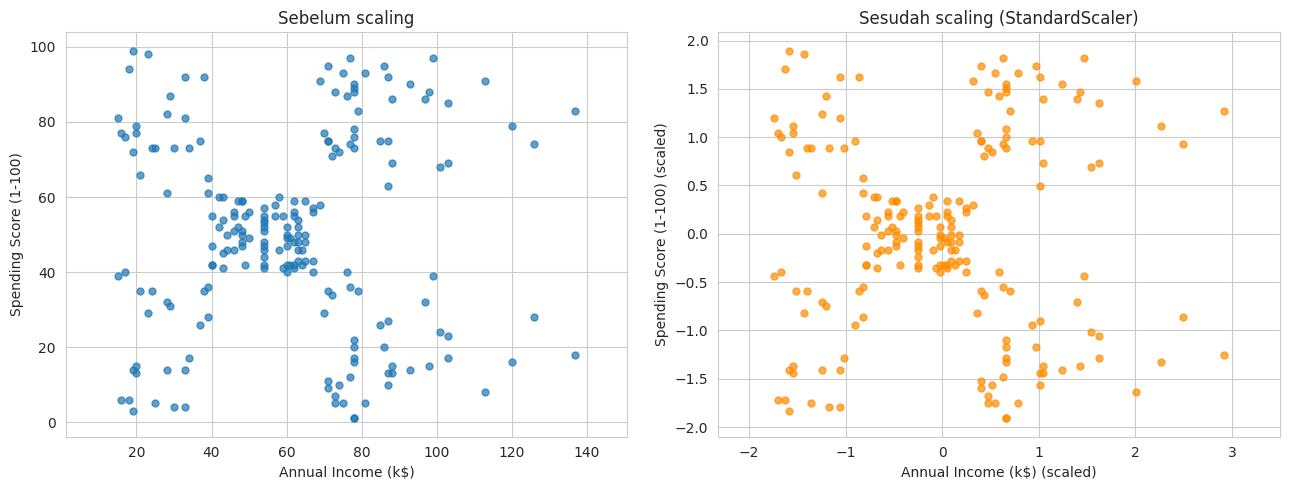

Rentang sebelum scaling:
Annual Income (k$)        122
Spending Score (1-100)     98

Rentang sesudah scaling:
Annual Income (k$)        4.66
Spending Score (1-100)    3.80


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], s=25, alpha=0.7)
axes[0].set_title("Sebelum scaling")
axes[0].set_xlabel(X.columns[0]); axes[0].set_ylabel(X.columns[1])
axes[0].axis("equal")   # skala sumbu disamakan agar perbedaan rentang terlihat jelas

axes[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], s=25, alpha=0.7, color="darkorange")
axes[1].set_title("Sesudah scaling (StandardScaler)")
axes[1].set_xlabel(X.columns[0] + " (scaled)"); axes[1].set_ylabel(X.columns[1] + " (scaled)")
axes[1].axis("equal")
plt.tight_layout()
plt.show()

print("Rentang sebelum scaling:")
print((X.max() - X.min()).to_string())
print("\nRentang sesudah scaling:")
print((X_scaled.max() - X_scaled.min()).round(2).to_string())

# Penjelasan:
# - DBSCAN, BIRCH memakai jarak Euclidean, sedangkan GMM memakai varians/kovarians tiap fitur.
#   Fitur dengan rentang lebih besar akan mendominasi jarak jika tidak di-scaling.
# - Pada dataset ini rentang Income (~15-137) dan Spending Score (~1-99) memang mirip, tetapi
#   scaling tetap penting agar eps/threshold punya makna yang konsisten (dalam satuan simpangan baku)
#   dan agar kode tetap benar jika fitur lain ditambahkan.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Jawaban:**

- **Alasan memilih kedua fitur:** keduanya numerik, berskala hampir sama, dan langsung menggambarkan perilaku ekonomi pelanggan (kemampuan membeli vs. kecenderungan membelanjakan). Dengan dua fitur, hasil clustering bisa divisualisasikan langsung di bidang 2D sehingga mudah diperiksa dan diinterpretasikan. Scatter plot EDA juga sudah menunjukkan struktur kelompok pada pasangan fitur ini.
- **Mengapa `CustomerID` tidak dipakai:** hanya nomor urut identitas, tidak membawa makna perilaku. Jika dimasukkan, algoritma berbasis jarak akan menganggap pelanggan bernomor berdekatan "mirip" padahal itu hanya urutan input, sehingga menambah noise dan merusak hasil.


# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Konfigurasi awal sesuai instruksi
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)
print("Label unik DBSCAN:", sorted(set(labels_dbscan)))

Label unik DBSCAN: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [9]:
def ringkas_label(labels, nama):
    s = pd.Series(labels).value_counts().sort_index()
    n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    print(f"=== {nama} ===")
    print("Jumlah anggota per label (-1 = noise):")
    print(s.to_string())
    print(f"Jumlah cluster (tanpa noise): {n_cluster}")
    print(f"Jumlah noise               : {n_noise} ({n_noise/len(labels)*100:.1f}%)")
    return n_cluster, n_noise

_ = ringkas_label(labels_dbscan, "DBSCAN eps=0.3, min_samples=5")

=== DBSCAN eps=0.3, min_samples=5 ===
Jumlah anggota per label (-1 = noise):
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Jumlah cluster (tanpa noise): 7
Jumlah noise               : 35 (17.5%)


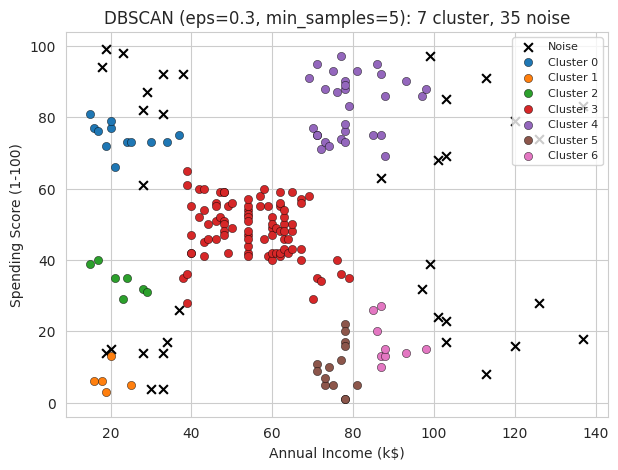

In [10]:
def plot_clusters(ax, data, labels, title, noise_label=-1):
    """Scatter plot berdasarkan label; noise digambar sebagai 'x' hitam."""
    palette = sns.color_palette("tab10", 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == noise_label:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], c="black", marker="x", s=40, label="Noise")
        else:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], color=palette[lab % 10], s=35,
                       edgecolor="k", linewidth=0.3, label=f"Cluster {lab}")
    ax.set_xlabel(data.columns[0]); ax.set_ylabel(data.columns[1])
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper right")

fig, ax = plt.subplots(figsize=(7, 5))
n_c = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_n = int((labels_dbscan == -1).sum())
plot_clusters(ax, X, labels_dbscan, f"DBSCAN (eps=0.3, min_samples=5): {n_c} cluster, {n_n} noise")
plt.show()

,eps,min_samples,n_cluster,n_noise,pct_noise,silhouette
0,0.2,3,13,44,22.0,0.470
1,0.2,5,7,77,38.5,0.586
2,0.2,8,2,116,58.0,0.603
3,0.2,10,1,129,64.5,NaN
4,0.3,3,9,14,7.0,0.472
5,0.3,5,7,35,17.5,0.524
6,0.3,8,5,72,36.0,0.593
7,0.3,10,4,88,44.0,0.607
8,0.4,3,4,10,5.0,0.395
9,0.4,5,4,15,7.5,0.478



Parameter DBSCAN terpilih: eps=0.4, min_samples=5


,eps,min_samples,n_cluster,n_noise,pct_noise,silhouette
9,0.4,5.0,4.0,15.0,7.5,0.478


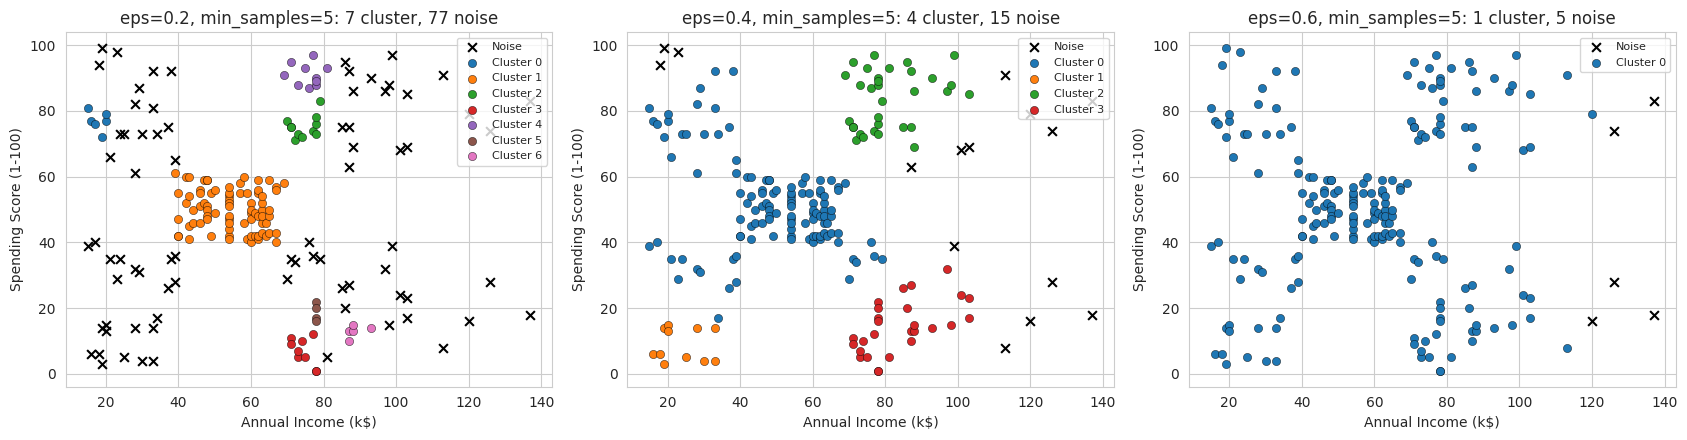

In [11]:
hasil_dbscan = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]:
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_c = len(set(lab)) - (1 if -1 in lab else 0)
        n_n = int((lab == -1).sum())
        mask = lab != -1
        # Silhouette hanya valid bila >= 2 cluster pada titik non-noise
        sil = silhouette_score(X_scaled[mask], lab[mask]) if n_c >= 2 else np.nan
        hasil_dbscan.append({"eps": eps, "min_samples": ms, "n_cluster": n_c,
                             "n_noise": n_n, "pct_noise": round(n_n / len(lab) * 100, 1),
                             "silhouette": round(sil, 3) if not np.isnan(sil) else np.nan})

tabel_dbscan = pd.DataFrame(hasil_dbscan)
display(tabel_dbscan)

# Catatan: silhouette DBSCAN dihitung tanpa noise, sehingga bisa tampak tinggi
# ketika banyak titik dibuang. Karena itu pemilihan parameter terbaik di bawah ini
# memakai batas noise maksimal 10% dan minimal 3 cluster.
kandidat = tabel_dbscan[(tabel_dbscan.pct_noise <= 10) & (tabel_dbscan.n_cluster >= 3)]
best_row = kandidat.sort_values("silhouette", ascending=False).iloc[0]
best_eps, best_ms = best_row["eps"], int(best_row["min_samples"])
print(f"\nParameter DBSCAN terpilih: eps={best_eps}, min_samples={best_ms}")
display(best_row.to_frame().T)

labels_dbscan_best = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X_scaled)

# Visualisasi pengaruh parameter
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (e, m) in zip(axes, [(0.2, 5), (best_eps, best_ms), (0.6, 5)]):
    lab = DBSCAN(eps=e, min_samples=m).fit_predict(X_scaled)
    n_c = len(set(lab)) - (1 if -1 in lab else 0)
    plot_clusters(ax, X, lab, f"eps={e}, min_samples={m}: {n_c} cluster, {(lab==-1).sum()} noise")
plt.tight_layout(); plt.show()

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban (berdasarkan tabel eksperimen):**

- **Pengaruh `eps`: Jadi `eps` kecil menghasilkan banyak noise dan cluster terpecah, sedangkan `eps` besar menggabungkan kelompok-kelompok berbeda menjadi satu.
- **Pengaruh `min_samples`:** Semakin besar `min_samples`, syarat kepadatan makin ketat sehingga lebih banyak titik menjadi noise dan cluster kecil hilang.
- **Kombinasi bermasalah:**
  - *Satu cluster besar:* semua `eps ≥ 0.6` (semua nilai `min_samples`), dan `eps=0.2, min_samples=10`.
  - *Terlalu banyak noise:* `eps=0.2` dengan `min_samples ≥ 5` (38–65% noise) dan `eps=0.3` dengan `min_samples ≥ 8` (36–44% noise).
- **Peringatan membaca silhouette:** silhouette DBSCAN dihitung tanpa noise sehingga bisa tampak tinggi justru ketika banyak titik dibuang (misalnya 0.607 dengan 44% noise). Karena itu parameter terbaik dipilih dengan batas noise ≤ 10% dan minimal 3 cluster, hasilnya `eps=0.4`, `min_samples=5` (4 cluster, 15 noise, silhouette 0.478).

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print("Jumlah subcluster (leaf) yang dibentuk tree:", len(birch.subcluster_centers_))

Jumlah subcluster (leaf) yang dibentuk tree: 10


In [13]:
print("Anggota tiap cluster BIRCH:")
print(pd.Series(labels_birch).value_counts().sort_index().to_string())
print("Jumlah cluster yang terbentuk:", len(set(labels_birch)))

Anggota tiap cluster BIRCH:
0     36
1    109
2      8
3     25
4     22
Jumlah cluster yang terbentuk: 5


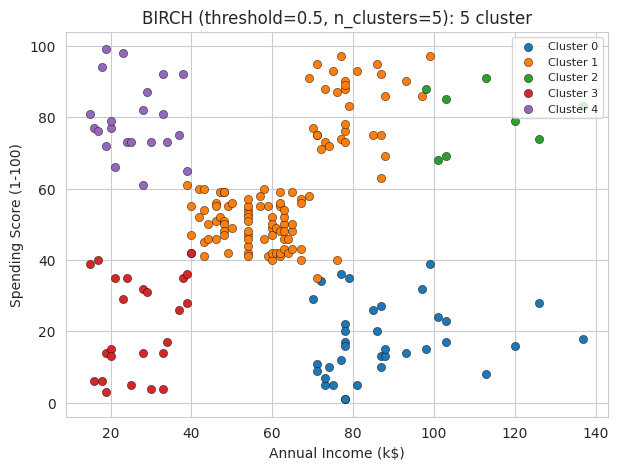

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_birch, f"BIRCH (threshold=0.5, n_clusters=5): {len(set(labels_birch))} cluster")
plt.show()

In [15]:
hasil_birch = []
for t in [0.3, 0.5, 0.7, 1.0]:
    b = Birch(threshold=t, n_clusters=5).fit(X_scaled)
    lab = b.labels_
    n_c = len(set(lab))
    sil = silhouette_score(X_scaled, lab) if n_c >= 2 else np.nan
    hasil_birch.append({"threshold": t, "n_subcluster": len(b.subcluster_centers_),
                        "n_cluster_akhir": n_c, "silhouette": round(sil, 3)})
tabel_birch = pd.DataFrame(hasil_birch)
display(tabel_birch)
print("Catatan: jika n_subcluster < n_clusters, BIRCH tidak bisa membentuk 5 cluster akhir.")

# Pengaruh n_clusters: n_clusters=None -> hasil akhir = subcluster hasil tree apa adanya
print("\nBIRCH tanpa n_clusters (n_clusters=None):")
hasil_none = []
for t in [0.3, 0.5, 0.7, 1.0]:
    b = Birch(threshold=t, n_clusters=None).fit(X_scaled)
    n_c = len(set(b.labels_))
    hasil_none.append({"threshold": t, "n_cluster_akhir": n_c,
                       "silhouette": round(silhouette_score(X_scaled, b.labels_), 3) if n_c >= 2 else np.nan})
display(pd.DataFrame(hasil_none))

# Parameter terbaik untuk evaluasi akhir: threshold dengan silhouette tertinggi
# yang masih menghasilkan tepat 5 cluster
best_t = tabel_birch[tabel_birch.n_cluster_akhir == 5].sort_values("silhouette", ascending=False).iloc[0]["threshold"]
labels_birch_best = Birch(threshold=best_t, n_clusters=5).fit_predict(X_scaled)
print(f"\nThreshold BIRCH terpilih: {best_t}")

,threshold,n_subcluster,n_cluster_akhir,silhouette
0,0.3,23,5,0.478
1,0.5,10,5,0.414
2,0.7,6,5,0.421
3,1.0,4,4,0.389


Catatan: jika n_subcluster < n_clusters, BIRCH tidak bisa membentuk 5 cluster akhir.

BIRCH tanpa n_clusters (n_clusters=None):


,threshold,n_cluster_akhir,silhouette
0,0.3,23,0.414
1,0.5,10,0.477
2,0.7,6,0.486
3,1.0,4,0.389



Threshold BIRCH terpilih: 0.3


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban:**

- **Pengaruh `threshold`:** semakin besar `threshold`, semakin sedikit subcluster yang dibentuk tree: 23 (0.3), 10 (0.5), 6 (0.7), 4 (1.0). Pada `threshold=1.0` hanya terbentuk 4 subcluster, lebih sedikit dari `n_clusters=5`, sehingga cluster akhir hanya 4 (muncul peringatan `ConvergenceWarning` dari BIRCH).
- **Perbedaan BIRCH vs DBSCAN untuk titik jauh:** DBSCAN secara eksplisit menandai titik terpencil sebagai noise (-1), misalnya 15 titik, kebanyakan income sangat tinggi (113–137 k$). BIRCH tidak punya label noise sehingga setiap titik harus masuk suatu cluster: pada `threshold=0.3` tiga pelanggan income ≈127 k$ membentuk cluster kecil sendiri (3 anggota), sedangkan pada `threshold=0.5` cluster kecil beranggota 8.
- **Pengaruh `n_clusters`:** ya, hasilnya berubah. Dengan `n_clusters=None`, hasil akhir sama dengan subcluster tree: 23, 10, 6, 4 cluster untuk threshold 0.3, 0.5, 0.7, 1.0. Dengan `n_clusters=5`, subcluster tersebut digabung lagi sampai tepat 5 cluster (selama jumlah subcluster ≥ 5), dan silhouette-nya berubah (0.478, 0.414, 0.421, 0.389).

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
gmm.fit(X_scaled)             # fit memakai algoritma EM
labels_gmm = gmm.predict(X_scaled)
print("EM konvergen:", gmm.converged_, "| iterasi:", gmm.n_iter_)

EM konvergen: True | iterasi: 5


In [17]:
print("Anggota tiap cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index().to_string())

proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f"P(cluster {k})" for k in range(5)]).round(3)
print("\nBeberapa baris probabilitas keanggotaan:")
display(proba_df.head(10))

# Titik dengan keanggotaan tidak pasti: probabilitas maksimum < 0.8
max_p = proba.max(axis=1)
tidak_pasti = np.where(max_p < 0.8)[0]
print(f"Titik dengan probabilitas maksimum < 0.8: {len(tidak_pasti)} dari {len(max_p)}")
print(f"Probabilitas maksimum rata-rata: {max_p.mean():.3f} | minimum: {max_p.min():.3f}")
print("\nContoh titik paling tidak pasti:")
idx = np.argsort(max_p)[:5]
display(pd.concat([X.iloc[idx].reset_index(drop=True), proba_df.iloc[idx].reset_index(drop=True)], axis=1))

Anggota tiap cluster GMM:
0    84
1    39
2    21
3    33
4    23

Beberapa baris probabilitas keanggotaan:


,P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),P(cluster 4)
0,0.000,0.0,0.001,0.0,0.999
1,0.000,0.0,1.000,0.0,0.000
2,0.000,0.0,0.000,0.0,1.000
3,0.000,0.0,1.000,0.0,0.000
4,0.000,0.0,0.002,0.0,0.998
5,0.000,0.0,1.000,0.0,0.000
6,0.000,0.0,0.000,0.0,1.000
7,0.000,0.0,1.000,0.0,0.000
8,0.000,0.0,0.000,0.0,1.000
9,0.001,0.0,0.998,0.0,0.000


Titik dengan probabilitas maksimum < 0.8: 6 dari 200
Probabilitas maksimum rata-rata: 0.983 | minimum: 0.503

Contoh titik paling tidak pasti:


,Annual Income (k$),Spending Score (1-100),P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),P(cluster 4)
0,70,29,0.497,0.0,0.000,0.503,0.000
1,40,42,0.611,0.0,0.000,0.000,0.388
2,40,42,0.611,0.0,0.000,0.000,0.388
3,28,61,0.279,0.0,0.675,0.000,0.046
4,79,35,0.772,0.0,0.000,0.228,0.000


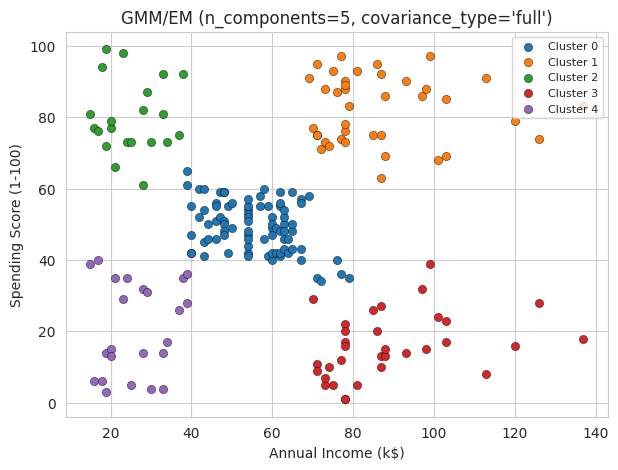

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_gmm, "GMM/EM (n_components=5, covariance_type='full')")
plt.show()

,n_components,silhouette,BIC,AIC
0,2,0.379,1153.9,1117.6
1,3,0.430,1151.7,1095.6
2,4,0.413,1103.8,1027.9
3,5,0.554,1058.7,963.0
4,6,0.517,1074.7,959.2
5,7,0.509,1087.3,952.1
6,8,0.430,1102.4,947.3


n_components dengan Silhouette tertinggi: 5
n_components dengan BIC terendah        : 5


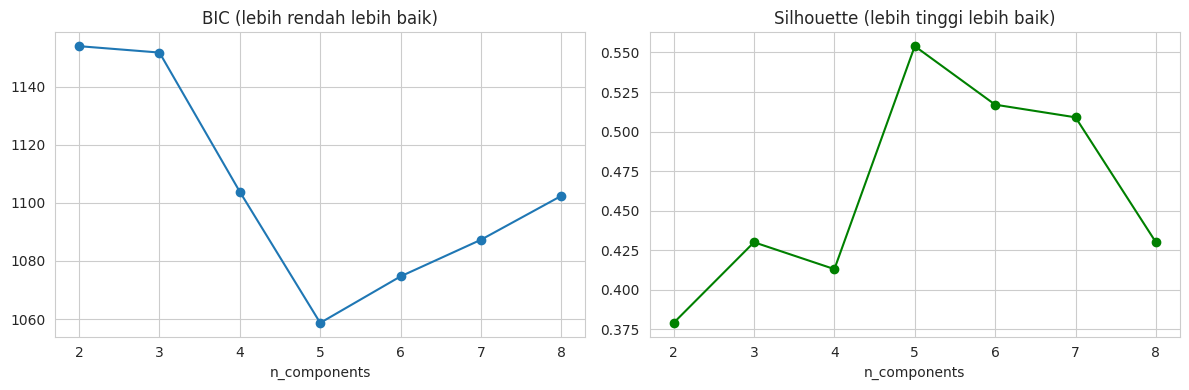

In [19]:
hasil_gmm = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=42).fit(X_scaled)
    lab = g.predict(X_scaled)
    hasil_gmm.append({"n_components": k, "silhouette": round(silhouette_score(X_scaled, lab), 3),
                      "BIC": round(g.bic(X_scaled), 1), "AIC": round(g.aic(X_scaled), 1)})
tabel_gmm = pd.DataFrame(hasil_gmm)
display(tabel_gmm)

k_sil = int(tabel_gmm.loc[tabel_gmm.silhouette.idxmax(), "n_components"])
k_bic = int(tabel_gmm.loc[tabel_gmm.BIC.idxmin(), "n_components"])
print(f"n_components dengan Silhouette tertinggi: {k_sil}")
print(f"n_components dengan BIC terendah        : {k_bic}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tabel_gmm.n_components, tabel_gmm.BIC, marker="o"); axes[0].set_title("BIC (lebih rendah lebih baik)")
axes[1].plot(tabel_gmm.n_components, tabel_gmm.silhouette, marker="o", color="green"); axes[1].set_title("Silhouette (lebih tinggi lebih baik)")
for a in axes: a.set_xlabel("n_components")
plt.tight_layout(); plt.show()

labels_gmm_best = GaussianMixture(n_components=k_bic, covariance_type="full", random_state=42).fit_predict(X_scaled)

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban:**

- **Arti probabilitas keanggotaan:** `predict_proba` memberi peluang sebuah titik berasal dari tiap komponen Gaussian (jumlahnya 1 per titik). Ini *soft assignment*, berbeda dengan label tegas. Pada model 5 komponen, probabilitas maksimum rata-rata 0.983, hanya 6 dari 200 titik yang probabilitas maksimumnya < 0.8, dan yang paling ambigu bernilai 0.503 (income 70, spending 29, berada di antara cluster tengah dan cluster income-tinggi–spending-rendah).
- **Efek mengubah `n_components`:** terlalu sedikit (2–4) menggabungkan segmen berbeda (silhouette 0.379–0.430); 5 memberi silhouette tertinggi 0.554; di atas 5 (6–8) segmen yang sebenarnya satu mulai dipecah (silhouette turun ke 0.509–0.430). BIC juga paling rendah di 5 (1058.7) lalu naik lagi.
- **Mengapa jumlah cluster harus ditentukan dulu:** GMM adalah model parametrik. Jumlah komponen menentukan banyaknya bobot, mean, dan kovarians yang diestimasi lewat EM, sehingga harus ditetapkan sebelum pelatihan. Karena itu dicari lewat perbandingan model (BIC, silhouette).
- **Silhouette tertinggi = BIC terendah?** Ya, keduanya memilih `n_components=5`. Catatan: AIC terus turun sampai k=8 (947.3), karena penalti kompleksitasnya lebih lemah daripada BIC, jadi AIC saja akan cenderung memilih model yang terlalu rumit.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
def evaluasi(X_data, labels, nama, noise_label=-1):
    """Hitung metrik internal. Titik noise dikeluarkan; metrik hanya dihitung bila valid."""
    labels = np.asarray(labels)
    mask = labels != noise_label
    n_noise = int((~mask).sum())
    X_eval, y_eval = np.asarray(X_data)[mask], labels[mask]
    n_cluster = len(set(y_eval))
    valid = (n_cluster >= 2) and (n_cluster < len(y_eval))
    return {
        "model": nama,
        "jumlah_cluster": n_cluster,
        "jumlah_noise": n_noise,
        "silhouette": silhouette_score(X_eval, y_eval) if valid else np.nan,
        "davies_bouldin": davies_bouldin_score(X_eval, y_eval) if valid else np.nan,
        "calinski_harabasz": calinski_harabasz_score(X_eval, y_eval) if valid else np.nan,
    }

# Uji cepat fungsi
print(evaluasi(X_scaled, labels_gmm, "GMM (uji)"))

{'model': 'GMM (uji)', 'jumlah_cluster': 5, 'jumlah_noise': 0, 'silhouette': 0.5536892843811245, 'davies_bouldin': 0.5760100302410824, 'calinski_harabasz': 244.94019698586325}


In [21]:
ringkasan = pd.DataFrame([
    evaluasi(X_scaled, labels_dbscan_best, f"DBSCAN (eps={best_eps}, min_samples={best_ms})"),
    evaluasi(X_scaled, labels_birch_best,  f"BIRCH (threshold={best_t}, n_clusters=5)"),
    evaluasi(X_scaled, labels_gmm_best,    f"GMM (n_components={k_bic}, full)"),
])
display(ringkasan.round(3))

print("Model terbaik per metrik:")
print("Silhouette        :", ringkasan.loc[ringkasan.silhouette.idxmax(), "model"])
print("Davies-Bouldin    :", ringkasan.loc[ringkasan.davies_bouldin.idxmin(), "model"])
print("Calinski-Harabasz :", ringkasan.loc[ringkasan.calinski_harabasz.idxmax(), "model"])

,model,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
0,"DBSCAN (eps=0.4, min_samples=5)",4,15,0.478,0.591,146.888
1,"BIRCH (threshold=0.3, n_clusters=5)",5,0,0.478,0.648,144.013
2,"GMM (n_components=5, full)",5,0,0.554,0.576,244.940


Model terbaik per metrik:
Silhouette        : GMM (n_components=5, full)
Davies-Bouldin    : GMM (n_components=5, full)
Calinski-Harabasz : GMM (n_components=5, full)


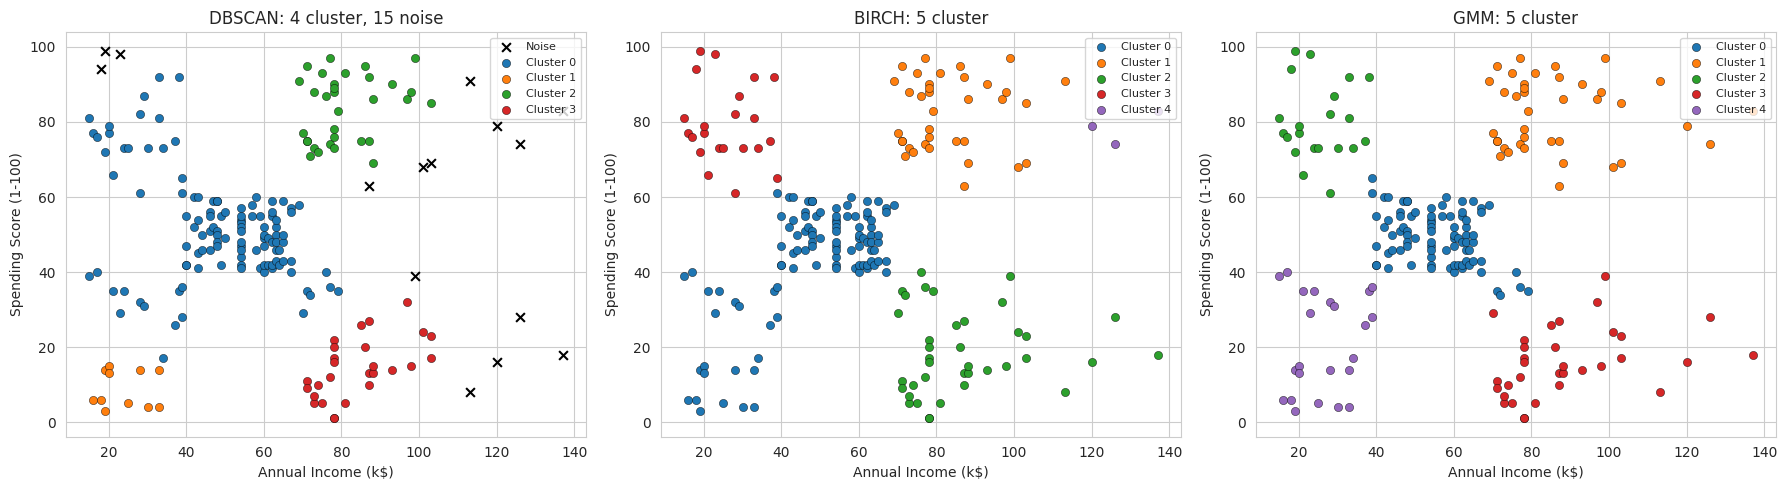

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
semua = [("DBSCAN", labels_dbscan_best), ("BIRCH", labels_birch_best), ("GMM", labels_gmm_best)]
for ax, (nama, lab) in zip(axes, semua):
    n_c = len(set(lab)) - (1 if -1 in lab else 0)
    n_n = int((lab == -1).sum())
    judul = f"{nama}: {n_c} cluster" + (f", {n_n} noise" if nama == "DBSCAN" else "")
    plot_clusters(ax, X, lab, judul)
plt.tight_layout(); plt.show()

In [23]:
def profil_cluster(labels, nama):
    d = X.copy()
    d["label"] = labels
    prof = d.groupby("label").agg(
        jumlah=("label", "size"),
        income_mean=(FEATURES[0], "mean"), income_median=(FEATURES[0], "median"),
        spending_mean=(FEATURES[1], "mean"), spending_median=(FEATURES[1], "median"),
    ).round(1)
    print(f"=== Profil cluster {nama} ===")
    if -1 in prof.index:
        print("(baris label -1 = noise, dianalisis terpisah)")
    display(prof)
    return prof

prof_dbscan = profil_cluster(labels_dbscan_best, "DBSCAN")
prof_birch  = profil_cluster(labels_birch_best,  "BIRCH")
prof_gmm    = profil_cluster(labels_gmm_best,    "GMM")

# Tambahan interpretasi: komposisi Gender per cluster GMM (Gender tidak dipakai sebagai input model)
print("Komposisi Gender per cluster GMM (%):")
display((pd.crosstab(labels_gmm_best, df_clean["Gender"], normalize="index") * 100).round(1))

=== Profil cluster DBSCAN ===
(baris label -1 = noise, dianalisis terpisah)


,jumlah,income_mean,income_median,spending_mean,spending_median
label,,,,,
-1,15,96.1,113.0,61.8,69.0
0,115,48.3,49.0,51.7,50.0
1,11,23.7,20.0,8.9,6.0
2,32,80.9,78.0,83.6,86.0
3,27,83.9,81.0,14.4,14.0


=== Profil cluster BIRCH ===


,jumlah,income_mean,income_median,spending_mean,spending_median
label,,,,,
0,101,48.2,50.0,43.4,47.0
1,36,83.1,78.0,82.4,85.5
2,38,87.0,80.0,18.6,16.5
3,22,25.7,24.5,79.4,77.0
4,3,127.7,126.0,78.7,79.0


=== Profil cluster GMM ===


,jumlah,income_mean,income_median,spending_mean,spending_median
label,,,,,
0,84,55.6,55.5,49.4,49.5
1,39,86.5,79.0,82.1,83.0
2,21,25.1,24.0,80.0,77.0
3,33,88.8,86.0,16.0,15.0
4,23,26.3,25.0,20.9,17.0


Komposisi Gender per cluster GMM (%):


Gender,Female,Male
row_0,,
0,59.5,40.5
1,53.8,46.2
2,57.1,42.9
3,45.5,54.5
4,60.9,39.1


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak, jumlah cluster ditentukan oleh `eps` dan `min_samples` | Opsional: `n_clusters=None` memakai subcluster apa adanya, atau diisi angka tertentu | Ya, `n_components` wajib ditentukan |
| Dapat memberi label noise secara eksplisit? | Ya | Tidak, semua titik masuk suatu cluster | Tidak, tetapi probabilitas keanggotaan rendah menandai titik ambigu |
| Parameter yang paling memengaruhi hasil | `eps` (sangat sensitif), lalu `min_samples` | `threshold` (menentukan jumlah subcluster), lalu `n_clusters` | `n_components`, lalu `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas berbasis kepadatan | Cenderung kompak/bulat | Elips (dengan `covariance_type='full'`) |
| Kelebihan | Mendeteksi noise; tidak perlu jumlah cluster; bentuk bebas | Cepat dan hemat memori; cocok untuk data besar | Soft assignment (probabilitas); bentuk elips fleksibel; punya kriteria pemilihan model (BIC) |
| Kekurangan | Sensitif terhadap parameter; mudah menggabungkan kelompok yang terhubung (chaining); sulit bila kepadatan antar kelompok berbeda | Hasil bergantung `threshold` dan urutan data; tidak ada label noise; asumsi cluster kompak | Perlu menentukan jumlah komponen; asumsi distribusi Gaussian; bisa terjebak optimum lokal (bergantung inisialisasi) |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

**Jawaban:**

1. DBSCAN dan BIRCH bekerja dengan jarak Euclidean, dan GMM dengan varians/kovarians. Fitur berskala besar akan mendominasi jarak jika tidak di-scaling. Pada dataset ini rentangnya mirip (122 vs 98), tetapi scaling membuat `eps` dan `threshold` bermakna dalam satuan simpangan baku dan menjaga hasil tetap valid bila fitur ditambah.

2. `eps` naik → cluster menyatu dan noise berkurang (pada min_samples=5: 7 cluster/77 noise di eps 0.2 menjadi 1 cluster di eps 0.6). `min_samples` naik → noise bertambah dan cluster kecil hilang (pada eps 0.3: 14 noise di min_samples 3 menjadi 88 noise di min_samples 10).

3. `threshold` besar → subcluster lebih sedikit (23 → 10 → 6 → 4). `n_clusters` menentukan berapa cluster akhir hasil penggabungan subcluster; jika subcluster lebih sedikit dari `n_clusters` (threshold 1.0), cluster akhir tidak bisa mencapai jumlah yang diminta.

4. probabilitas adalah peluang titik berasal dari tiap komponen Gaussian. EM bekerja berulang: *E-step* menghitung probabilitas keanggotaan (responsibility) tiap titik pada tiap komponen berdasarkan parameter saat ini; *M-step* memperbarui bobot, mean, dan kovarians tiap komponen dengan probabilitas itu sebagai bobot. Proses diulang sampai log-likelihood konvergen (pada notebook ini konvergen dalam 5 iterasi)

5. GMM dengan 5 komponen. Kelimanya sesuai dengan lima kelompok yang terlihat di scatter plot, tidak ada titik tanpa cluster, dan probabilitasnya menunjukkan seberapa pasti keanggotaan. DBSCAN menggabungkan beberapa segmen, dan BIRCH menghasilkan satu cluster 101 anggota yang mencampur segmen berbeda ditambah satu cluster 3 anggota.

6. pada eksperimen ini ketiga metrik sepakat bahwa GMM terbaik (Silhouette 0.554, Davies-Bouldin 0.576, Calinski-Harabasz 244.9, dibanding DBSCAN 0.478/0.591/146.9 dan BIRCH 0.478/0.648/144.0). Tetap perlu hati-hati: (a) metrik DBSCAN dihitung tanpa 15 titik noise sehingga tidak sepenuhnya setara dengan dua model lain; (b) metrik internal cenderung menyukai cluster kompak/konveks, yang cocok dengan asumsi GMM; (c) silhouette bisa menyesatkan, seperti DBSCAN yang mencapai 0.607 padahal 44% titik dibuang, dan BIRCH dan DBSCAN yang sama-sama 0.478 padahal segmentasinya berbeda.

7. **Karakteristik cluster (GMM, median income/spending, jumlah anggota):**
   - Cluster 0 (84): ≈55.5 k$ / ≈49.5, **pelanggan menengah (standar)**.
   - Cluster 1 (39): ≈79 k$ / ≈83, **pelanggan premium (kaya & boros)**, target utama promosi.
   - Cluster 2 (21): ≈24 k$ / ≈77, **muda/impulsif (income rendah, belanja tinggi)**.
   - Cluster 3 (33): ≈86 k$ / ≈15, **hemat/selektif (income tinggi, belanja rendah)**, potensi untuk ditarik dengan penawaran khusus.
   - Cluster 4 (23): ≈25 k$ / ≈17, **hemat karena keterbatasan (income rendah, belanja rendah)**.
   - Nama "muda" hanya dugaan; `Age` tidak dipakai dalam model sehingga perlu dicek terpisah.
   - Komposisi Gender tiap cluster cukup seimbang (perempuan 45–61%), jadi gender tidak membedakan segmen secara jelas.
   `
8. hanya dua fitur sehingga informasi lain (usia, gender, frekuensi belanja) tidak dipakai, dan segmen bisa berubah jika fitur ditambah. Data hanya 200 pelanggan, jadi estimasi kepadatan DBSCAN dan estimasi kovarians GMM kurang stabil (satu atau dua titik bisa mengubah hasil). Tidak ada label sebenarnya, sehingga evaluasi hanya memakai metrik internal. Data juga satu *snapshot* dari satu mal, sehingga belum tentu berlaku untuk pelanggan lain.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

**Jawaban:**

- **Algoritma paling berguna:** **EM/GMM dengan 5 komponen**. Ia unggul di ketiga metrik (Silhouette 0.554, Davies-Bouldin 0.576, Calinski-Harabasz 244.9), cocok dengan struktur 5 kelompok di scatter plot, memberi segmen yang mudah dinamai, dan BIC/silhouette sepakat pada k=5.

- **Parameter terpilih:**
  - DBSCAN `eps=0.4`, `min_samples=5` (silhouette tertinggi dengan syarat noise ≤ 10% dan ≥ 3 cluster).
  - BIRCH `threshold=0.3`, `n_clusters=5` (silhouette tertinggi di antara threshold yang menghasilkan tepat 5 cluster).
  - GMM `n_components=5`, `covariance_type='full'`, `random_state=42` (BIC terendah dan silhouette tertinggi).
- DBSCAN berbasis kepadatan, tanpa jumlah cluster, dan bisa menandai noise, tetapi sensitif terhadap `eps` dan menggabungkan segmen yang bersambung. BIRCH efisien lewat ringkasan tree, namun tidak memberi noise dan hasilnya sangat bergantung pada `threshold`. GMM memodelkan data sebagai campuran Gaussian, memberi probabilitas keanggotaan, dan cocok untuk cluster berbentuk elips, tetapi jumlah komponen harus ditentukan.

- 
  - Menambahkan `Age` (dan `Gender` yang di-encode) sebagai fitur, atau memakai PCA bila fitur banyak.
  - Mencoba `covariance_type` lain (`tied`, `diag`, `spherical`) dan beberapa `random_state`/`n_init` untuk menguji stabilitas GMM.
  - Memilih `eps` DBSCAN dengan grafik k-distance, serta mencoba HDBSCAN yang lebih tahan terhadap perbedaan kepadatan.
  - Membandingkan dengan K-Means dan Agglomerative Clustering sebagai baseline.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)